# 1.02 — Estacionalidad y anomalías

**Proyecto:** MiBici — TC5044.10, Equipo 04
**Autor:** Erik Román Cortez
**Insumo:** `interim_v1` (`data/interim/trips`)

## 1. Objetivo

Analizar los cambios de mediano y largo plazo en las salidas de MiBici para decidir después:

- si el modelo se entrena con toda la historia o solo con un periodo;
- si 2020–2021 se trata como un régimen especial;
- si ciertos días deben marcarse o excluirse del entrenamiento.

**Preguntas:**
1. ¿Existen patrones estacionales por mes?
2. ¿Qué meses tienen sistemáticamente mayor o menor volumen?
3. ¿Qué días son claramente atípicos?
4. ¿Qué comportamiento diferente se observa en 2020–2021?
5. ¿El periodo 2020–2021 debería tratarse de manera especial en el modelado?

## 2. Datos utilizados

- **Archivo:** `data/interim/trips` (Parquet particionado por año), historia completa 2014-12 a 2026-09.
- **Columnas:** `started_at`, `origin_station_id`.
- **Definición de salida (regla común 5.1):** un viaje contado en `origin_station_id` a la hora de `started_at`. Se usan **todos** los viajes de interim, incluidos los marcados con `flag_*`.
- **Estaciones activas de un mes o un día:** estaciones con al menos una salida en ese periodo (calculadas desde los viajes, como permite el plan).
- Horas en hora local de Guadalajara, sin conversión de zona horaria.

## 3. Método

1. **Agregación:** se resumen los ~39 M de viajes a una serie **diaria** y una **mensual** (salidas y estaciones activas). Después se libera la memoria de los viajes.
2. **Normalización por tamaño de la red:** la red creció con los años. Para no confundir expansión con demanda, se usa **salidas por día por estación activa**. Dividir entre días evita que febrero (28 días) parezca un mes débil solo por ser corto.
3. **Estacionalidad:** índice estacional = valor del mes / promedio de su año (1.0 = mes típico). Solo años completos (2015–2025).
4. **2020–2021:** índice = mes / mismo mes de 2019, para medir la caída y la recuperación.
5. **Días atípicos:** cociente = salidas del día / mediana de las 8 semanas previas **del mismo día de la semana**. Atípico si el cociente es < 0.5 o > 1.5. Cada día atípico se cruza con un calendario de festivos y vacaciones, y con la cobertura horaria del día, para separar **comportamiento real** de **posibles fallas de registro**.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from dateutil.easter import easter

from mibici.config import FIGURES_DIR, INTERIM_DATA_DIR, REPORTS_DIR

PREFIX = "1.02-erc"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({"figure.figsize": (12, 4.5), "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.max_rows", 120)

DIAS = ["lunes", "martes", "miércoles", "jueves", "viernes", "sábado", "domingo"]


def guardar(fig, nombre):
    ruta = FIGURES_DIR / f"{PREFIX}-{nombre}.png"
    fig.savefig(ruta, dpi=120, bbox_inches="tight")
    print(f"Figura guardada: reports/figures/{ruta.name}")

2026-10-24 15:23:35.733 | INFO     | mibici.config:<module>:12 - PROJ_ROOT path is: /home/user/mlops/MiBici


## 4. Análisis

### 4.1 Carga y agregación

Se leen solo dos columnas (regla 5.3). Con eso se construyen las series diaria y mensual, y después se borra la tabla de viajes para liberar RAM.

In [2]:
trips = pd.read_parquet(INTERIM_DATA_DIR / "trips", columns=["started_at", "origin_station_id"])
assert pd.api.types.is_datetime64_any_dtype(trips["started_at"]), "started_at no es datetime"

print(f"Viajes: {len(trips):,}")
print(f"Periodo: {trips['started_at'].min()} → {trips['started_at'].max()}")
print(f"Memoria: {trips.memory_usage(deep=True).sum() / 1e9:.2f} GB")

Viajes: 39,078,226
Periodo: 2014-12-01 00:33:47 → 2026-09-30 23:59:48
Memoria: 0.51 GB


In [3]:
# Serie diaria: salidas, estaciones activas y primera/última salida (cobertura horaria del día)
diario = trips.groupby(trips["started_at"].dt.normalize()).agg(
    salidas=("origin_station_id", "size"),
    estaciones_activas=("origin_station_id", "nunique"),
    primera_salida=("started_at", "min"),
    ultima_salida=("started_at", "max"),
)

# Serie mensual
mensual = trips.groupby(trips["started_at"].dt.to_period("M")).agg(
    salidas=("origin_station_id", "size"),
    estaciones_activas=("origin_station_id", "nunique"),
)
mensual.index.name = "mes"

del trips  # liberar memoria: a partir de aquí solo se usan las series agregadas

# Días del calendario sin ningún viaje registrado → se agregan con 0 salidas
rango = pd.date_range(diario.index.min(), diario.index.max(), freq="D")
dias_sin_datos = rango.difference(diario.index)
diario = diario.reindex(rango)
diario["salidas"] = diario["salidas"].fillna(0).astype(int)
diario["estaciones_activas"] = diario["estaciones_activas"].fillna(0).astype(int)
diario.index.name = "fecha"

# Métrica normalizada mensual: salidas por día por estación activa
dias_con_datos = (diario["salidas"] > 0).groupby(diario.index.to_period("M")).sum()
mensual["dias_con_datos"] = dias_con_datos.reindex(mensual.index)
mensual["salidas_dia"] = mensual["salidas"] / mensual["dias_con_datos"]
mensual["salidas_dia_estacion"] = mensual["salidas_dia"] / mensual["estaciones_activas"]

print(f"Días en el calendario: {len(diario):,} | días sin ningún viaje: {len(dias_sin_datos)}")
if len(dias_sin_datos):
    print("Días sin datos:", [d.date().isoformat() for d in dias_sin_datos[:20]])
mensual.tail(12).round(2)

Días en el calendario: 4,322 | días sin ningún viaje: 0


,salidas,estaciones_activas,dias_con_datos,salidas_dia,salidas_dia_estacion
mes,,,,,
2025-10,420064,368,31,13550.45,36.82
2025-11,380328,367,30,12677.6,34.54
2025-12,335420,368,31,10820.0,29.4
2026-01,357180,368,31,11521.94,31.31
2026-02,333756,368,28,11919.86,32.39
2026-03,376243,369,31,12136.87,32.89
2026-04,351851,368,30,11728.37,31.87
2026-05,315895,371,31,10190.16,27.47
2026-06,355303,422,30,11843.43,28.07


### 4.2 Serie mensual: total vs. por estación activa

Figura guardada: reports/figures/1.02-erc-monthly-series.png


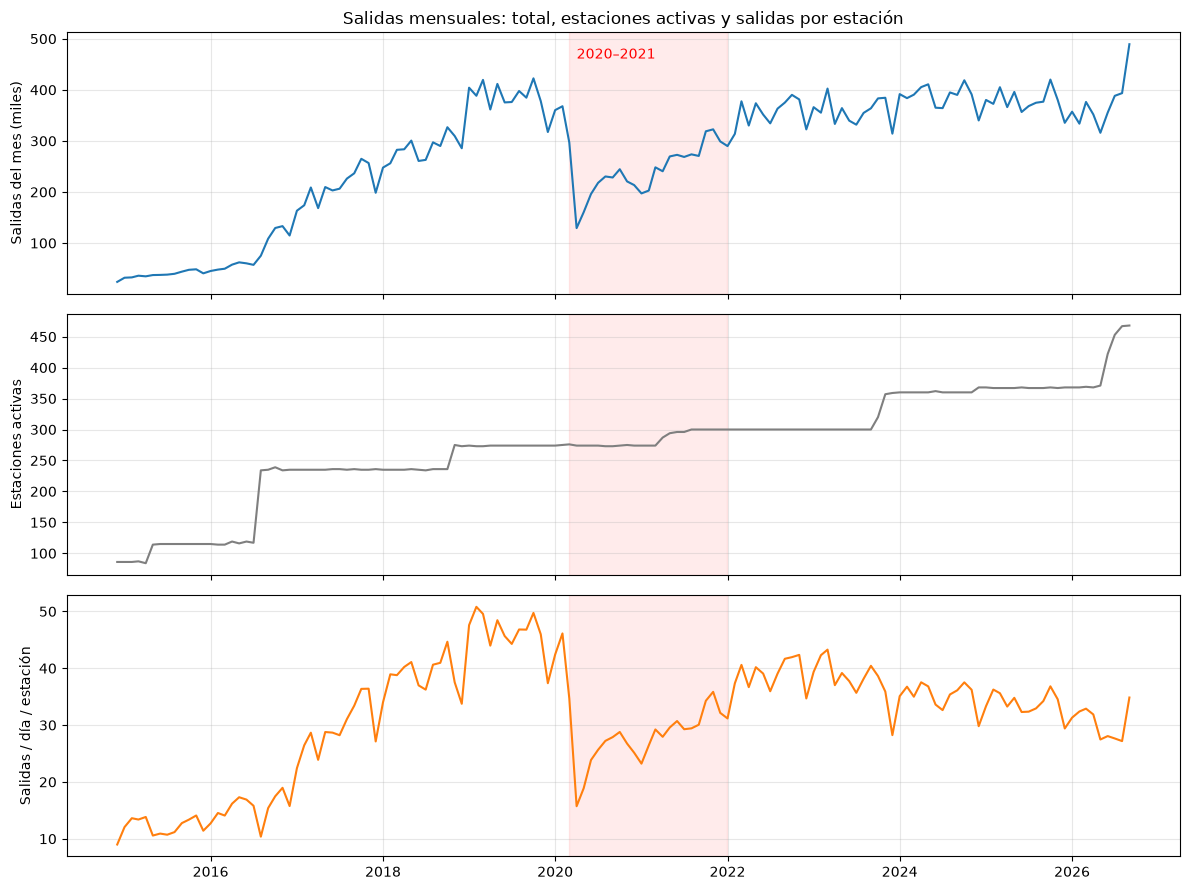

In [4]:
x = mensual.index.to_timestamp()
fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)

axes[0].plot(x, mensual["salidas"] / 1e3, color="tab:blue")
axes[0].set_ylabel("Salidas del mes (miles)")
axes[0].set_title("Salidas mensuales: total, estaciones activas y salidas por estación")

axes[1].plot(x, mensual["estaciones_activas"], color="tab:gray")
axes[1].set_ylabel("Estaciones activas")

axes[2].plot(x, mensual["salidas_dia_estacion"], color="tab:orange")
axes[2].set_ylabel("Salidas / día / estación")

for ax in axes:
    ax.axvspan(pd.Timestamp("2020-03-01"), pd.Timestamp("2021-12-31"), color="red", alpha=0.08)
axes[0].text(pd.Timestamp("2020-04-01"), axes[0].get_ylim()[1] * 0.9, "2020–2021", color="red")

fig.tight_layout()
guardar(fig, "monthly-series")
plt.show()

**Interpretación:**

- **El total y la serie por estación cuentan historias distintas.** El total mensual sube de ~25 mil (2014) a ~400 mil viajes (2019), pero buena parte de ese crecimiento viene de la red: las estaciones activas crecen en **escalones** (≈85 → 115 en 2015, → 235 en ago-2016, → 275 en 2018, → 300 en 2021, → 360 en sep-2023 y → 468 en jun–sep 2026).
- **La demanda por estación también creció hasta 2019** (de ~10 a ~50 salidas/día/estación): el sistema maduró, no solo se expandió.
- **2020–2021:** caída abrupta en abril de 2020 (el total baja de ~370 mil a ~130 mil viajes) y una recuperación lenta que dura casi dos años.
- **Desde 2022** el total vuelve a niveles parecidos a 2019 (~320–420 mil por mes), pero las salidas por estación se quedan **más abajo** (~30–40). Cada expansión (2023, 2026) baja el promedio por estación, porque las estaciones nuevas arrancan con menos uso.
- **Implicación:** para comparar periodos hay que normalizar por estaciones activas; el total solo confunde expansión con demanda.

### 4.3 Perfil estacional por mes

Índice estacional = salidas/día/estación del mes ÷ promedio de su año. Solo años completos. El promedio de referencia **excluye 2020 y 2021** para que la pandemia no deforme el perfil "normal".

Figura guardada: reports/figures/1.02-erc-seasonal-profile.png


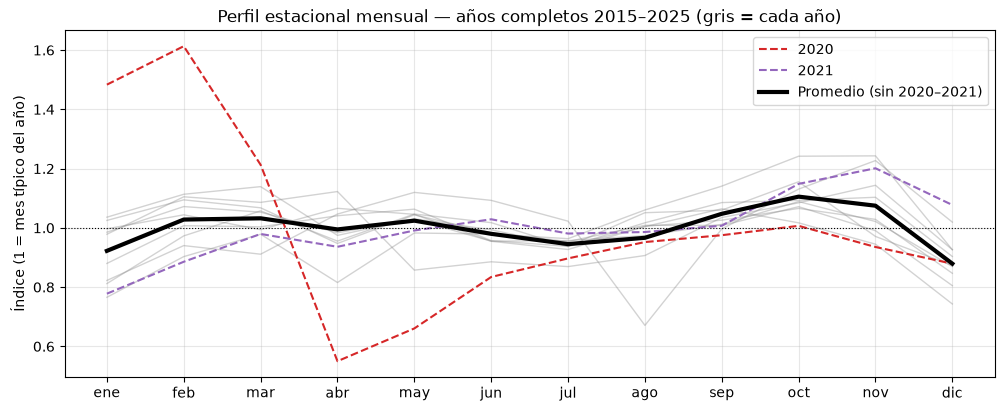

anio,promedio_sin_2020_2021,desv_est
dic,0.879,0.079
ene,0.922,0.103
jul,0.945,0.04
ago,0.966,0.119
jun,0.98,0.056
abr,0.995,0.089
may,1.024,0.072
feb,1.028,0.076
mar,1.032,0.068
sep,1.047,0.046


In [5]:
m = mensual[["salidas_dia_estacion"]].copy()
m["anio"] = m.index.year
m["mes_num"] = m.index.month
anios_completos = m.groupby("anio").size().loc[lambda s: s == 12].index
m = m[m["anio"].isin(anios_completos)]
m["indice"] = m["salidas_dia_estacion"] / m.groupby("anio")["salidas_dia_estacion"].transform("mean")

perfil = m.pivot(index="mes_num", columns="anio", values="indice")
anios_normales = [a for a in perfil.columns if a not in (2020, 2021)]
perfil["promedio_sin_2020_2021"] = perfil[anios_normales].mean(axis=1)
perfil["desv_est"] = perfil[anios_normales].std(axis=1)

MESES = ["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"]
fig, ax = plt.subplots()
for a in anios_normales:
    ax.plot(perfil.index, perfil[a], color="gray", alpha=0.35, lw=1)
for a, c in [(2020, "tab:red"), (2021, "tab:purple")]:
    if a in perfil.columns:
        ax.plot(perfil.index, perfil[a], color=c, ls="--", lw=1.5, label=str(a))
ax.plot(perfil.index, perfil["promedio_sin_2020_2021"], color="black", lw=3, label="Promedio (sin 2020–2021)")
ax.axhline(1, color="black", lw=0.8, ls=":")
ax.set_xticks(range(1, 13), MESES)
ax.set_ylabel("Índice (1 = mes típico del año)")
ax.set_title(f"Perfil estacional mensual — años completos {anios_completos.min()}–{anios_completos.max()} (gris = cada año)")
ax.legend()
guardar(fig, "seasonal-profile")
plt.show()

resumen_meses = perfil[["promedio_sin_2020_2021", "desv_est"]].set_axis(MESES).round(3)
resumen_meses.sort_values("promedio_sin_2020_2021")

**Interpretación:**

- **Hay estacionalidad mensual moderada y estable**: las líneas grises de los distintos años siguen la misma forma, con desviación estándar de 0.04 a 0.12 entre años.
- **Meses altos:** octubre (1.11), noviembre (1.08) y septiembre (1.05). **Meses bajos:** diciembre (0.88), enero (0.92) y julio (0.95). Entre el mes más alto y el más bajo hay **23 %** de diferencia en salidas por estación.
- Los meses bajos coinciden con **periodos vacacionales** (fin de año y verano), lo que sugiere que buena parte de la demanda es de traslados a escuela y trabajo. La temporada de lluvias (jun–sep) no produce una caída clara a nivel mensual: septiembre está entre los meses más altos.
- **2020 y 2021 rompen el patrón por completo** (2020 alto al inicio y desplomado después; 2021 al revés). No sirven para estimar la estacionalidad normal.
- **Implicación:** conviene incluir el **mes** (o una variable de periodo vacacional) como predictor.

### 4.4 2020–2021 frente a 2019

Índice = salidas/día/estación del mes ÷ el mismo mes de 2019. Un valor de 0.6 significa 40 % menos actividad por estación que en 2019.

Figura guardada: reports/figures/1.02-erc-covid-vs-2019.png


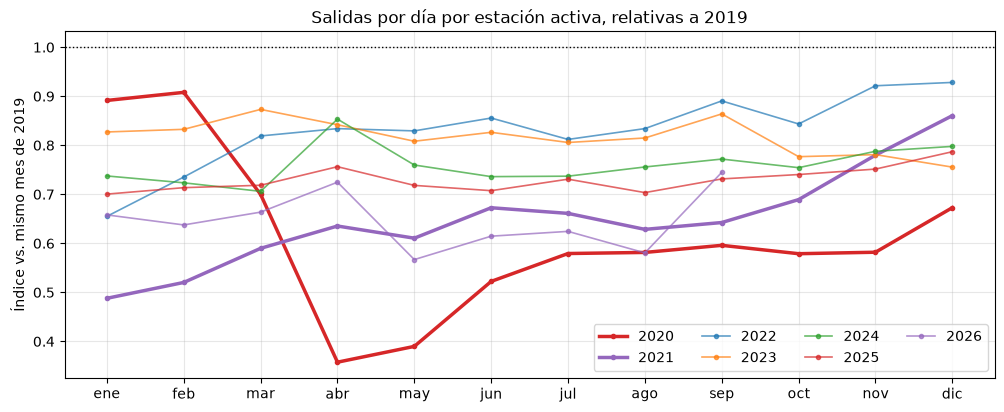

,2020,2021,2022,2023,2024,2025,2026
ene,0.89,0.49,0.66,0.83,0.74,0.7,0.66
feb,0.91,0.52,0.74,0.83,0.72,0.71,0.64
mar,0.7,0.59,0.82,0.87,0.71,0.72,0.66
abr,0.36,0.64,0.83,0.84,0.85,0.76,0.72
may,0.39,0.61,0.83,0.81,0.76,0.72,0.57
jun,0.52,0.67,0.86,0.83,0.74,0.71,0.61
jul,0.58,0.66,0.81,0.81,0.74,0.73,0.62
ago,0.58,0.63,0.83,0.81,0.76,0.7,0.58
sep,0.6,0.64,0.89,0.86,0.77,0.73,0.74
oct,0.58,0.69,0.84,0.78,0.75,0.74,<NA>


In [6]:
base_2019 = mensual.loc[mensual.index.year == 2019, "salidas_dia_estacion"]
base_2019.index = base_2019.index.month

indice_2019 = {}
for anio in range(2020, mensual.index.year.max() + 1):
    serie = mensual.loc[mensual.index.year == anio, "salidas_dia_estacion"]
    indice_2019[anio] = pd.Series(serie.values / base_2019.loc[serie.index.month].values, index=serie.index.month)
indice_2019 = pd.DataFrame(indice_2019)

fig, ax = plt.subplots()
colores = {2020: "tab:red", 2021: "tab:purple"}
for anio in indice_2019.columns:
    estilo = {"lw": 2.5, "color": colores[anio]} if anio in colores else {"lw": 1.2, "alpha": 0.7}
    ax.plot(indice_2019.index, indice_2019[anio], marker="o", ms=3, label=str(anio), **estilo)
ax.axhline(1, color="black", lw=1, ls=":")
ax.set_xticks(range(1, 13), MESES)
ax.set_ylabel("Índice vs. mismo mes de 2019")
ax.set_title("Salidas por día por estación activa, relativas a 2019")
ax.legend(ncol=4)
guardar(fig, "covid-vs-2019")
plt.show()

indice_2019.set_axis(MESES[: len(indice_2019)]).round(2)

**Interpretación:**

- **La caída empieza en marzo de 2020** (0.70 frente a 2019) y toca fondo en **abril de 2020 (0.36)**: 64 % menos salidas por estación que en abril de 2019.
- **2021 es un año de transición**: arranca en 0.49 y cierra en 0.86. Se parece más a 2020 que a un año normal.
- **La demanda por estación no volvió al nivel de 2019.** El primer mes con índice ≥ 0.9 es noviembre de 2022, y desde 2023 el índice se estabiliza en **~0.70–0.80**. En 2026 baja a ~0.6, por la llegada de ~100 estaciones nuevas con poco uso.
- Enero y febrero de 2020 ya estaban un 10 % abajo de 2019, antes de la pandemia. 2019 fue un año pico, así que como línea base es exigente.
- **Implicación:** 2020–2021 es un **régimen distinto**: no solo cambia el volumen, cambia también el patrón mensual. Los años desde 2022 forman un régimen nuevo y relativamente estable, con menor demanda por estación.

### 4.5 Días atípicos

**Criterio:** cociente = salidas del día ÷ mediana de las **8 semanas previas del mismo día de la semana** (mínimo 4 semanas de historia). Se usa la mediana porque no se deja arrastrar por otros días atípicos, y "mismo día de la semana" porque un domingo no se compara con un martes. Umbrales: **< 0.5 = bajo**, **> 1.5 = alto**.

**Explicación de cada día:**
- calendario de festivos oficiales de México y periodos vacacionales (Semana Santa/Pascua, fin de año) → **comportamiento real**;
- día sin viajes o con menos de 12 h entre la primera y la última salida → **posible falla del sistema o registro incompleto**;
- el resto → **por explicar** (lluvia fuerte, eventos).

In [7]:
UMBRAL_BAJO, UMBRAL_ALTO, SEMANAS = 0.5, 1.5, 8

d = diario.copy()
d["dia_semana"] = d.index.dayofweek
d["esperado"] = d.groupby("dia_semana")["salidas"].transform(
    lambda s: s.shift(1).rolling(SEMANAS, min_periods=4).median()
)
d["cociente"] = d["salidas"] / d["esperado"].replace(0, np.nan)
d["tipo"] = np.select([d["cociente"] < UMBRAL_BAJO, d["cociente"] > UMBRAL_ALTO], ["bajo", "alto"], default="")
d["horas_cobertura"] = (d["ultima_salida"] - d["primera_salida"]).dt.total_seconds() / 3600


def n_lunes(anio, mes, n):
    primero = pd.Timestamp(anio, mes, 1)
    return primero + pd.Timedelta(days=(0 - primero.dayofweek) % 7 + 7 * (n - 1))


def calendario_mx(anio):
    pascua = pd.Timestamp(easter(anio))
    return {
        pd.Timestamp(anio, 1, 1): "Año Nuevo",
        n_lunes(anio, 2, 1): "Día de la Constitución (puente)",
        n_lunes(anio, 3, 3): "Natalicio de Benito Juárez (puente)",
        pascua - pd.Timedelta(days=3): "Jueves Santo",
        pascua - pd.Timedelta(days=2): "Viernes Santo",
        pd.Timestamp(anio, 5, 1): "Día del Trabajo",
        pd.Timestamp(anio, 9, 16): "Día de la Independencia",
        pd.Timestamp(anio, 11, 2): "Día de Muertos",
        n_lunes(anio, 11, 3): "Revolución Mexicana (puente)",
        pd.Timestamp(anio, 12, 12): "Día de la Virgen de Guadalupe",
        pd.Timestamp(anio, 12, 24): "Nochebuena",
        pd.Timestamp(anio, 12, 25): "Navidad",
        pd.Timestamp(anio, 12, 31): "Fin de año",
    }


festivos = {}
for a in range(d.index.year.min(), d.index.year.max() + 1):
    festivos.update(calendario_mx(a))


def causa(fecha):
    if fecha in festivos:
        return festivos[fecha]
    pascua = pd.Timestamp(easter(fecha.year))
    if pascua - pd.Timedelta(days=7) <= fecha <= pascua + pd.Timedelta(days=7):
        return "Vacaciones de Semana Santa / Pascua"
    if (fecha.month == 12 and fecha.day >= 20) or (fecha.month == 1 and fecha.day <= 6):
        return "Vacaciones de fin de año"
    if pd.Timestamp("2020-03-16") <= fecha <= pd.Timestamp("2020-05-31"):
        return "Inicio de la pandemia COVID-19 (hipótesis)"
    return ""


def clasificar(fila):
    if fila["salidas"] == 0 or fila["horas_cobertura"] < 12:
        return "posible falla / registro incompleto"
    if fila["causa"]:
        return "comportamiento real (calendario)"
    return "por explicar"


atipicos = d[d["tipo"] != ""].copy()
atipicos["causa"] = [causa(f) for f in atipicos.index]
atipicos["clasificacion"] = atipicos.apply(clasificar, axis=1)
atipicos["dia"] = atipicos["dia_semana"].map(dict(enumerate(DIAS)))

print(f"Días evaluados: {d['cociente'].notna().sum():,} | atípicos: {len(atipicos)} "
      f"({len(atipicos) / d['cociente'].notna().sum():.1%})")
pd.crosstab(atipicos["clasificacion"], atipicos["tipo"], margins=True)

Días evaluados: 4,294 | atípicos: 136 (3.2%)


/tmp/ipykernel_1354/1608811773.py:4: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  d["dia_semana"] = d.index.dayofweek
/tmp/ipykernel_1354/1608811773.py:15: Pandas4Warning: Timestamp.dayofweek is deprecated and will be removed in a future version. Use Timestamp.day_of_week instead.
  return primero + pd.Timedelta(days=(0 - primero.dayofweek) % 7 + 7 * (n - 1))


tipo,alto,bajo,All
clasificacion,,,
comportamiento real (calendario),0,97,97
por explicar,31,8,39
All,31,105,136


Figura guardada: reports/figures/1.02-erc-daily-atypical-days.png


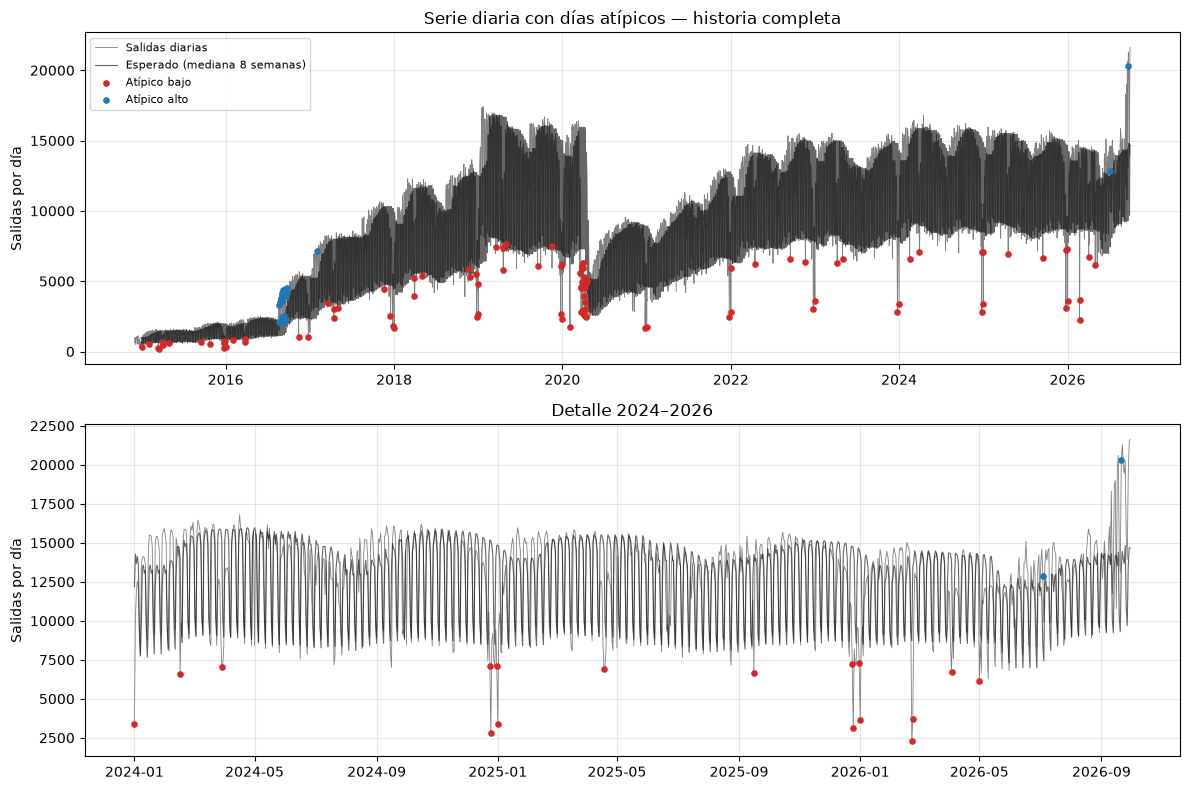

In [8]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8))
colores_tipo = {"bajo": "tab:red", "alto": "tab:blue"}
for ax, desde in [(axes[0], d.index.min()), (axes[1], pd.Timestamp("2024-01-01"))]:
    tramo = d[d.index >= desde]
    ax.plot(tramo.index, tramo["salidas"], color="gray", lw=0.6, label="Salidas diarias")
    ax.plot(tramo.index, tramo["esperado"], color="black", lw=0.8, alpha=0.6, label="Esperado (mediana 8 semanas)")
    for tipo, color in colores_tipo.items():
        pts = atipicos[(atipicos["tipo"] == tipo) & (atipicos.index >= desde)]
        ax.scatter(pts.index, pts["salidas"], color=color, s=14, zorder=3, label=f"Atípico {tipo}")
    ax.set_ylabel("Salidas por día")
axes[0].set_title("Serie diaria con días atípicos — historia completa")
axes[1].set_title("Detalle 2024–2026")
axes[0].legend(loc="upper left", fontsize=8)
fig.tight_layout()
guardar(fig, "daily-atypical-days")
plt.show()

#### Lista de días atípicos identificados

Se guarda completa en `reports/1.02-erc-atypical-days.csv` (archivo pequeño, se versiona como evidencia).

In [9]:
cols = ["dia", "salidas", "esperado", "cociente", "tipo", "horas_cobertura", "causa", "clasificacion"]
lista = atipicos[cols].round({"esperado": 0, "cociente": 2, "horas_cobertura": 1})
lista.to_csv(REPORTS_DIR / f"{PREFIX}-atypical-days.csv", index_label="fecha")
print(f"Guardado: reports/{PREFIX}-atypical-days.csv ({len(lista)} días)")

print("\nAtípicos por año y clasificación:")
display(pd.crosstab(lista.index.year, lista["clasificacion"]))
print("\nDías atípicos 'por explicar' (revisar uno por uno):")
display(lista[lista["clasificacion"] == "por explicar"])

Guardado: reports/1.02-erc-atypical-days.csv (136 días)

Atípicos por año y clasificación:


clasificacion,comportamiento real (calendario),por explicar
row_0,,
2015,12,2
2016,5,29
2017,6,2
2018,8,1
2019,10,0
2020,30,0
2021,3,0
2022,5,0
2023,4,0



Días atípicos 'por explicar' (revisar uno por uno):


,dia,salidas,esperado,cociente,tipo,horas_cobertura,causa,clasificacion
fecha,,,,,,,,
2015-03-15,domingo,258,622.0,0.41,bajo,23.6,,por explicar
2015-10-23,viernes,524,1650.0,0.32,bajo,23.1,,por explicar
2016-08-19,viernes,3292,2123.0,1.55,alto,17.9,,por explicar
2016-08-20,sábado,2065,1337.0,1.54,alto,17.9,,por explicar
2016-08-25,jueves,3553,2206.0,1.61,alto,17.9,,por explicar
2016-08-26,viernes,3595,2128.0,1.69,alto,18.0,,por explicar
2016-08-27,sábado,2175,1394.0,1.56,alto,17.9,,por explicar
2016-08-28,domingo,1995,1128.0,1.77,alto,17.8,,por explicar
2016-08-29,lunes,3734,2229.0,1.68,alto,18.0,,por explicar


**Interpretación:**

- Con el criterio de mediana móvil del mismo día de la semana se identifican **136 días atípicos (3.2 % de los días)**: 105 bajos y 31 altos.
- **97 de los 105 días bajos se explican por el calendario**: Año Nuevo, Navidad, Semana Santa, 16 de septiembre, etc. Se repiten todos los años, así que son **comportamiento real y predecible**, no errores. Además, 30 de ellos son de 2020 (inicio de la pandemia).
- **No hay evidencia de fallas de registro:** ningún día del calendario quedó sin viajes y todos los atípicos tienen una cobertura horaria normal (~18 h hasta 2023 y ~24 h después).
- **Los 39 días "por explicar" caen en tres grupos:**
  1. **Escalón por expansión (29 días, 19-ago a 23-sep de 2016):** las estaciones activas pasan de ~120 a ~235 en agosto de 2016 y la mediana móvil tarda 8 semanas en ajustarse. **No son días atípicos**: es un cambio de nivel. Lo mismo explica los altos de julio y septiembre de 2026 (expansión de 371 a 468 estaciones).
  2. **Eventos extraordinarios identificados:** 23-oct-2015, día en que el **huracán Patricia** tocó tierra en Jalisco (cociente 0.32); **22 y 23 de febrero de 2026**, días de **bloqueos y violencia en Jalisco** (cocientes 0.26 y 0.27, los más bajos de toda la serie fuera del calendario).
  3. **Sin explicación confirmada:** 2015-03-15, 2016-11-13, 2017-01-30 (alto), 2017-12-16, 2018-11-28 y 2024-02-16. Son posibles lluvias fuertes, eventos o incidencias operativas, y quedan como hipótesis.
- **Implicación:** los festivos y las vacaciones no se excluyen; se modelan con una variable `es_festivo`/`periodo_vacacional`. Los eventos extraordinarios no recurrentes (huracán, bloqueos) sí conviene **marcarlos o excluirlos** del entrenamiento y de la evaluación, porque no se pueden pronosticar con el calendario.

### 4.6 Distribución por año

Salidas diarias por estación activa (excluye días sin viajes). Si las cajas de 2020–2021 se separan claramente del resto, el periodo es un régimen distinto.

Figura guardada: reports/figures/1.02-erc-yearly-distribution.png


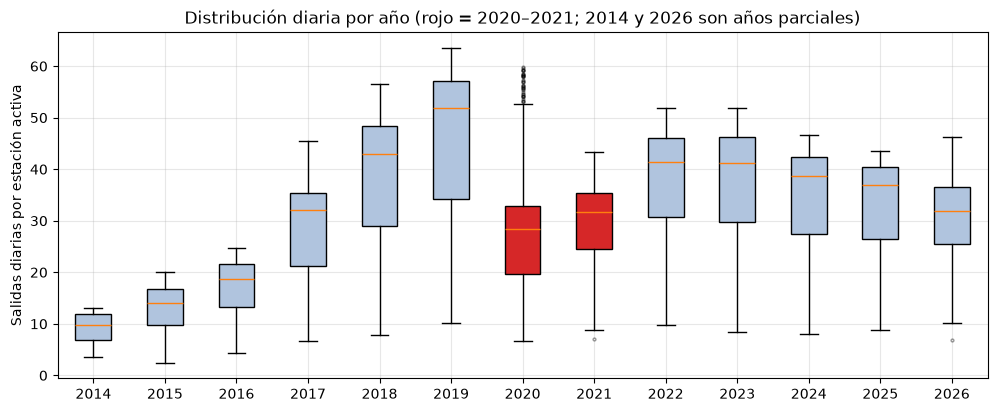

,count,mean,50%,std
fecha,,,,
2014,31.0,9.19,9.82,2.69
2015,365.0,13.36,14.03,3.93
2016,366.0,17.40,18.74,4.87
2017,365.0,29.75,32.02,9.10
2018,365.0,39.29,42.99,10.98
2019,365.0,46.51,51.91,13.03
2020,366.0,28.78,28.36,12.32
2021,365.0,30.12,31.73,7.44
2022,365.0,38.49,41.41,9.04


In [10]:
d_valid = d[d["salidas"] > 0].copy()
d_valid["salidas_por_estacion"] = d_valid["salidas"] / d_valid["estaciones_activas"]
anios = sorted(d_valid.index.year.unique())
datos_anio = [d_valid.loc[d_valid.index.year == a, "salidas_por_estacion"] for a in anios]

fig, ax = plt.subplots()
bp = ax.boxplot(datos_anio, tick_labels=[str(a) for a in anios], showfliers=True,
                flierprops={"markersize": 2, "alpha": 0.4}, patch_artist=True)
for caja, a in zip(bp["boxes"], anios):
    caja.set_facecolor("tab:red" if a in (2020, 2021) else "lightsteelblue")
ax.set_ylabel("Salidas diarias por estación activa")
ax.set_title("Distribución diaria por año (rojo = 2020–2021; 2014 y 2026 son años parciales)")
guardar(fig, "yearly-distribution")
plt.show()

d_valid.groupby(d_valid.index.year)["salidas_por_estacion"].describe()[["count", "mean", "50%", "std"]].round(2)

**Interpretación:**

- **2014–2019: crecimiento sostenido** de la mediana diaria por estación (de 9.8 a 51.9). Es la etapa de arranque y maduración del sistema.
- **2020 se separa claramente**: la mediana cae a 28.4 y la dispersión es la mayor de la serie (desv. est. 12.3), por la mezcla de meses prepandemia y de confinamiento. **2021** sigue abajo (31.7).
- **2022–2023 forman una meseta** (~41), y desde 2024 hay un **descenso gradual** (38.8 → 37.0 → 31.9 en 2026) que coincide con las expansiones de 2023 y 2026.
- La dispersión desde 2022 es menor y similar entre años (7–9), señal de que el comportamiento diario es **más estable** que en la etapa de crecimiento.

### 4.7 Resumen numérico para las conclusiones

In [11]:
pm = perfil["promedio_sin_2020_2021"]
covid = indice_2019.get(2020, pd.Series(dtype=float))
print(f"Mes más alto: {MESES[pm.idxmax() - 1]} ({pm.max():.2f}) | mes más bajo: {MESES[pm.idxmin() - 1]} ({pm.min():.2f}) "
      f"| amplitud: {(pm.max() - pm.min()):.0%} del mes típico")
if not covid.empty:
    print(f"2020: índice mínimo vs. 2019 = {covid.min():.2f} en {MESES[covid.idxmin() - 1]}")
recuperado = indice_2019.stack().loc[lambda s: s >= 0.9]
recuperado = recuperado[recuperado.index.get_level_values(1) > 2020].sort_index(level=[1, 0])
if len(recuperado):
    mes_r, anio_r = recuperado.index[0]
    print(f"Primer mes después de 2020 con índice ≥ 0.9: {MESES[mes_r - 1]} {anio_r}")
print(f"Días sin ningún viaje: {len(dias_sin_datos)} | días atípicos: {len(lista)}")
print(lista["clasificacion"].value_counts().to_string())

Mes más alto: oct (1.11) | mes más bajo: dic (0.88) | amplitud: 23% del mes típico
2020: índice mínimo vs. 2019 = 0.36 en abr
Primer mes después de 2020 con índice ≥ 0.9: nov 2022
Días sin ningún viaje: 0 | días atípicos: 136
clasificacion
comportamiento real (calendario)    97
por explicar                        39


## 5. Hallazgos

1. **Estacionalidad mensual moderada y estable** (±12 % alrededor del mes típico): octubre es el mes más alto y diciembre el más bajo. Los meses bajos coinciden con vacaciones escolares (diciembre–enero y julio).
2. **2020–2021 es un régimen distinto:** caída de 64 % por estación en abril de 2020, un 2021 de transición, y un patrón mensual que no se parece al de ningún otro año.
3. **Después de la pandemia la demanda total se recuperó, pero la demanda por estación no:** desde 2023 está en ~70–80 % del nivel de 2019, en parte porque la red creció.
4. **3.2 % de los días son atípicos, y casi todos los bajos son festivos o vacaciones recurrentes.** No se encontraron días con fallas de registro.
5. **Eventos extraordinarios detectados:** el huracán Patricia (23-oct-2015) y los bloqueos en Jalisco (22 y 23-feb-2026).
6. **Las expansiones de la red generan escalones de nivel** (2016, 2023, 2026) que un detector ingenuo confunde con anomalías.

## 6. Implicaciones para el modelado

- **Periodo de entrenamiento:** usar **desde 2022-01**. Excluir 2014–2019 (etapa de crecimiento, con una red y una demanda muy distintas) y **2020–2021** (régimen pandémico). Si se quisiera más historia, la alternativa es incluir 2020–2021 con una variable `regimen_covid`, pero no se recomienda para un pronóstico del día siguiente.
- **Variables de calendario:** `mes`, `es_festivo` (con el calendario usado en este notebook) y `periodo_vacacional` (Semana Santa/Pascua, fin de año y julio).
- **Días a marcar:** crear una marca `evento_extraordinario` para 2015-10-23, 2026-02-22 y 2026-02-23, y excluirlos del entrenamiento y de la evaluación. Los festivos **no** se excluyen.
- **Tamaño de la red:** cualquier comparación o feature agregada debe normalizarse por estaciones activas. La expansión de 2026 cambia el nivel promedio por estación 
## 7. Limitaciones y riesgos

- No hay datos de clima ni de eventos: los días "por explicar" quedan como hipótesis.
- El calendario de festivos se construyó con reglas generales y no incluye festivos locales, puentes extraordinarios ni el calendario escolar exacto.
- La mediana móvil de 8 semanas tarda en adaptarse a los **cambios de nivel por expansión**, y los marca como atípicos (29 días de 2016). Una mejora sería calcular el cociente sobre salidas por estación activa.
- "Estación activa" se define por tener al menos una salida en el periodo; una estación abierta sin uso no cuenta.
- La cobertura horaria diaria pasa de ~18 h (hasta ~2023) a ~24 h: posible cambio en el horario de servicio, que conviene confirmar con el equipo antes de comparar horas entre periodos.
- 2014 (solo diciembre) y 2026 (hasta septiembre) son años incompletos.
- **Riesgo para producción:** si la red sigue creciendo, los niveles por estación seguirán desplazándose, y es un caso de *data drift* a monitorear en la Fase 3.

## 8. Conclusión

La demanda de MiBici tiene una estacionalidad mensual estable y predecible, y casi todos sus días atípicos son festivos o vacaciones que se repiten cada año, así que se pueden modelar con variables de calendario en vez de eliminarse. El periodo 2020–2021 es un régimen distinto en volumen y en patrón, y debe tratarse aparte. **Recomendación para `processed_v1`: entrenar con datos desde enero de 2022**, agregar `mes`, `es_festivo` y `periodo_vacacional`, y excluir solo los eventos extraordinarios identificados (huracán Patricia y los bloqueos de febrero de 2026).

**Fuentes de los eventos:** [Ruptura360 — narcobloqueos en Jalisco](https://ruptura360.mx/observatorio/narcobloqueos-en-jalisco-resumen/), [El Congresista — bloqueos en Jalisco, 23 de febrero](https://elcongresista.mx/politica/jalisco/bloqueos-jalisco-23-febrero), [CS Monitor — Hurricane Patricia, 23-oct-2015](https://csmonitor.com/layout/set/amphtml/World/Global-News/2015/1023/Mexico-braces-for-Hurricane-Patricia-now-strongest-hurricane-on-record).

---
*Uso de IA: el código de este notebook se elaboró con apoyo de Claude (Anthropic, modelo Opus)